# 6 · L'opérateur sans matrice (matrix-free)

*Notebook 6 du cours. Il suppose les notebooks 4 (matrice élémentaire $\mathbf K_e^0$, connectivité) et 5 (solveurs direct et gradient conjugué).*

Jusqu'ici, pour résoudre $\widetilde{\mathbf K}\mathbf u=\mathbf f$, nous avons **assemblé** la matrice $\mathbf K$ (notebooks 2 à 4) puis appelé un solveur (notebook 5). Mais le gradient conjugué n'utilise de $\mathbf K$ qu'une seule chose : le produit $\mathbf K\mathbf v$. Et ce produit peut se calculer **sans jamais former $\mathbf K$**, élément par élément. Sur une grille régulière, c'est particulièrement simple : tous les éléments ont la **même** matrice $\mathbf K_e^0$, seul un coefficient $w_e$ (la rigidité SIMP $s_e$) change.

**Plan.**
1. Le principe : $\mathbf K=\sum_e w_e\,\mathbf A_e^\top\mathbf K_e^0\mathbf A_e$ et ses trois étapes (rassembler, multiplier, ajouter) ;
2. Les conditions aux limites : l'opérateur $\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P)$ ;
3. Validation : cinq vérifications contre un oracle à boucles, plus un cas physique (poutre console contre Timoshenko) ;
4. Mesures : mémoire et temps, 2D et 3D, face à la matrice creuse ;
5. Le même code pour une inconnue par nœud (Poisson) ;
6. Brancher l'opérateur dans les solveurs du notebook 5 ;
7. Limites et pièges.

Ce notebook promeut dans `src/aeroptimizer/fem/operators.py` la classe `StructuredFEOperator` (`matvec`, `diag`, `assemble_csr`, `dK_contract`) et branche `ScipyDirect.prepare` et `TorchCG.prepare` de `fem/solvers.py`.

In [1]:
import sys, time, math, subprocess, textwrap
from pathlib import Path

import numpy as np
import scipy.sparse as sp
import torch
import matplotlib.pyplot as plt
from torch.utils._python_dispatch import TorchDispatchMode
from torch.utils._pytree import tree_leaves

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))

from aeroptimizer.fem import elements as el
from aeroptimizer.fem.operators import StructuredFEOperator
from aeroptimizer.fem.solvers import DirectHandle, ScipyDirect, TorchCG
from aeroptimizer.grid import Grid, Connectivity
from aeroptimizer.materials import Orthotropic

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

## 1. Le principe : rassembler, multiplier, ajouter

Au notebook 2, la matrice globale s'écrit comme somme de contributions élémentaires. Avec $\mathbf A_e$ la matrice (de 0 et de 1) qui extrait de $\mathbf u$ les $m$ degrés de liberté de l'élément $e$ ($m=8$ en 2D, $24$ en 3D mécanique),

$$
\mathbf K=\sum_{e}\mathbf A_e^\top\,\big(w_e\,\mathbf K_e^0\big)\,\mathbf A_e
\qquad\Longrightarrow\qquad
\mathbf K\mathbf v=\sum_{e}\mathbf A_e^\top\,\big(w_e\,\mathbf K_e^0\,(\mathbf A_e\mathbf v)\big).
$$

La seconde forme se lit de droite à gauche en trois étapes, et **aucune ne demande $\mathbf K$** :

1. **rassembler** (*gather*) : $\mathbf v_e=\mathbf A_e\mathbf v$, c'est-à-dire lire dans $\mathbf v$ les $m$ valeurs de chaque élément (un tableau `v[edof]` de forme $(N_e, m)$) ;
2. **multiplier** : $\mathbf f_e=w_e\,\mathbf K_e^0\mathbf v_e$, un petit produit dense $m\times m$ **identique pour tous les éléments** (grille régulière), donc un seul produit matrice-matrice $(N_e,m)\times(m,m)$ ;
3. **ajouter** (*scatter-add*) : $\mathbf y=\sum_e\mathbf A_e^\top\mathbf f_e$, chaque $\mathbf f_e$ est ajouté aux $m$ cases correspondantes de $\mathbf y$.

Une grille de $2\times2$ éléments avec une inconnue par nœud (comme la température) suffit à voir la structure. La table `edof` (notebook 4) donne, pour chaque élément, les numéros de ses nœuds.

edof (une ligne par élément, colonnes = les 4 nœuds locaux) :
[[0 1 3 4]
 [1 2 4 5]
 [3 4 6 7]
 [4 5 7 8]]


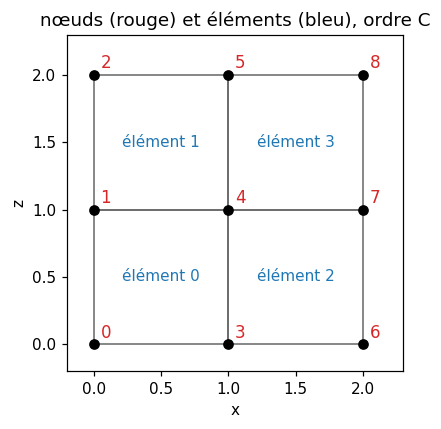

Le nœud central 4 appartient à 4 éléments : il recevra 4 contributions.


In [2]:
def laplace_q1(d, h):
    # matrice élémentaire de diffusion Q1 : somme de poids x det J x grad(N)^T grad(N), aux points de Gauss
    _, wq = el.gauss_points(d)
    G = el.shape_grads(d, h)                       # (points de Gauss, 2^d, d)
    return math.prod(hk / 2 for hk in h) * torch.einsum("g,gai,gbi->ab", wq, G, G)

g = Grid((2, 2), (1.0, 1.0))
conn = Connectivity(g, 1)
print("edof (une ligne par élément, colonnes = les 4 nœuds locaux) :")
print(conn.edof.numpy())

fig, ax = plt.subplots(figsize=(4.2, 4.0))
for ix in range(3):
    for iz in range(3):
        ax.plot(ix, iz, "ko"); ax.text(ix + 0.05, iz + 0.05, str(ix * 3 + iz), color="C3", fontsize=11)
for ix in range(2):
    for iz in range(2):
        ax.add_patch(plt.Rectangle((ix, iz), 1, 1, fill=False, ec="0.4"))
        ax.text(ix + 0.5, iz + 0.5, f"élément {ix * 2 + iz}", ha="center", va="center", color="C0")
ax.set_xlim(-0.2, 2.3); ax.set_ylim(-0.2, 2.3); ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("z"); ax.set_title("nœuds (rouge) et éléments (bleu), ordre C")
plt.tight_layout(); plt.show()
print("Le nœud central 4 appartient à", int((conn.edof == 4).sum()), "éléments : il recevra 4 contributions.")

## 2. L'algorithme en trois lignes

On donne à chaque élément un coefficient différent $w_e$ et on applique les trois étapes. Pour juger le résultat, on le compare à la matrice $\mathbf K$ **assemblée par boucles** (la méthode lente du notebook 2) : somme sur les éléments, puis sur les paires de degrés de liberté locaux.

In [3]:
Ke0 = laplace_q1(2, g.h)
w = torch.tensor([1.0, 2.0, 3.0, 4.0])                  # un coefficient par élément
v = torch.arange(9.0) ** 1.5                            # un champ quelconque aux 9 nœuds

ve = v[conn.edof]                                       # 1. rassembler          : (4 éléments, 4 nœuds)
fe = (ve @ Ke0.T) * w[:, None]                          # 2. multiplier          : un seul produit (4,4)@(4,4)
y = torch.zeros(9).index_add_(0, conn.edof.reshape(-1), fe.reshape(-1))   # 3. ajouter
print("formes :", tuple(ve.shape), tuple(fe.shape), tuple(y.shape))

def assemble_loops(conn, Ke0, w):
    # oracle lent : K = somme sur e de w_e Ke0 placée aux lignes/colonnes edof[e]
    N = int(conn.edof.max()) + 1
    K = np.zeros((N, N))
    for e, dofs in enumerate(conn.edof.tolist()):
        for i, gi in enumerate(dofs):
            for j, gj in enumerate(dofs):
                K[gi, gj] += float(w[e]) * float(Ke0[i, j])
    return K

K_ref = assemble_loops(conn, Ke0, w)
print("écart relatif à K @ v  :", np.linalg.norm(y.numpy() - K_ref @ v.numpy()) / np.linalg.norm(K_ref @ v.numpy()))

formes : (4, 4) (4, 4) (9,)
écart relatif à K @ v  : 3.027602259339176e-16


Le résultat est exact à la précision machine. Un piège classique se cache dans l'étape 3. Plusieurs éléments écrivent dans la même case (le nœud 4 ci-dessus reçoit 4 contributions). L'écriture naïve `y[edof] += fe` **ne les additionne pas** : en cas d'indices répétés, une seule des contributions survit. Seul `index_add_` additionne correctement.

In [4]:
y_naif = torch.zeros(9)
y_naif[conn.edof] += fe                                  # tentation : l'indexation avancée
print("y_naif - y, nœud par nœud :", (y_naif - y).numpy())
print("nombre d'éléments par nœud :", torch.bincount(conn.edof.reshape(-1)).numpy())

y_naif - y, nœud par nœud : [  0.       2.3987   0.      -1.7974   1.5336 -10.631    0.     -20.4959   0.    ]
nombre d'éléments par nœud : [1 2 1 2 4 2 1 2 1]


L'erreur est nulle aux quatre coins (un seul élément) et non nulle partout où au moins deux éléments se partagent le nœud (jusqu'au centre, qui en reçoit quatre). Retenons : **le *scatter-add* se fait avec `index_add_`**, jamais avec `+=` sur un index avancé. (`index_add_` sait aussi être dérivé par autograd, ce que le notebook 7 utilisera.)

Cet algorithme est ce que fait `StructuredFEOperator.matvec` dans `src`. Avant de l'utiliser en mécanique, il reste à traiter les appuis.

## 3. Les conditions aux limites : $\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P)$

Une structure sans appui peut se déplacer librement : $\mathbf K$ est **singulière** (3 modes rigides en 2D, 6 en 3D, voir le notebook 4), et ni le CG ni la factorisation ne fonctionnent. On bloque des degrés de liberté. Plutôt que de supprimer ces lignes et colonnes (ce qui change la taille et la numérotation), le projet **remplace** les lignes et colonnes bloquées par celles de l'identité. Avec $\mathbf P$ la matrice diagonale valant 1 sur les degrés libres et 0 sur les bloqués,

$$
\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P),\qquad
\widetilde{\mathbf K}\mathbf u=\mathbf P\mathbf f \;\Rightarrow\; \mathbf u_{\text{bloqué}}=\mathbf 0,\quad \mathbf K_{ff}\mathbf u_f=\mathbf f_f.
$$

Les degrés libres résolvent exactement le système réduit, les bloqués valent 0, et $\widetilde{\mathbf K}$ reste symétrique, définie positive, de même taille que $\mathbf K$. Dans `matvec`, cela s'écrit : masquer $\mathbf v$ aux degrés bloqués avant l'étape 1, masquer le résultat, puis y remettre $\mathbf v$ (l'identité) sur les degrés bloqués.

On construit une console 2D (encastrée à gauche, chargée sur l'extrémité libre) et on vérifie ces affirmations sur une petite grille avec la matrice dense.

In [5]:
def cantilever(shape, h=None, nu=0.3):
    # console encastrée sur la face x=0, force totale -1 suivant z répartie sur la face x=L ; E = 1
    d = len(shape)
    h = h or (1.0,) * d
    g = Grid(shape, h)
    mat = Orthotropic.isotropic(1.0, nu)
    C0 = mat.stiffness(2, "stress") if d == 2 else mat.stiffness(3)
    Ke0 = el.elasticity_ke0(d, h, C0)
    per_face = g.n_nodes // (shape[0] + 1)           # nœuds d'une face x = cste (ordre C : x varie le plus lentement)
    fixed = torch.zeros(g.n_dofs(d), dtype=torch.bool)
    fixed[: d * per_face] = True                      # tous les ddl des nœuds 0 .. per_face-1 (face x=0)
    f = torch.zeros(g.n_dofs(d))
    f[d * (g.n_nodes - per_face) + d - 1 :: d] = -1.0 / per_face   # composante z des nœuds de la face x=L
    return StructuredFEOperator(g, Connectivity(g, d), Ke0, d, fixed), f

op, f = cantilever((8, 4))
w = torch.ones(op.grid.n_elems)

# K sans appuis (aucun ddl bloqué) : on garde le même Ke0, mais fixed_mask vide
libre = StructuredFEOperator(op.grid, Connectivity(op.grid, 2), op.Ke0, 2, torch.zeros(op.n_dofs, dtype=torch.bool))
K_libre = libre.assemble_csr(w).toarray()
K_tilde = op.assemble_csr(w).toarray()
print("plus petites valeurs propres de K  (sans appuis) :", np.linalg.eigvalsh(K_libre)[:4])
print("plus petites valeurs propres de K~ (avec appuis) :", np.linalg.eigvalsh(K_tilde)[:4])

libres = op.free_mask.numpy()
u_reduit = np.linalg.solve(K_libre[np.ix_(libres, libres)], f.numpy()[libres])   # on supprime lignes et colonnes
u = DirectHandle(op.assemble_csr(w)).solve(f).numpy()
print("écart avec la résolution du système réduit :", np.abs(u[libres] - u_reduit).max(), "| déplacement aux ddl bloqués :", np.abs(u[~libres]).max())

plus petites valeurs propres de K  (sans appuis) : [-0.     -0.      0.      0.0329]
plus petites valeurs propres de K~ (avec appuis) : [0.0019 0.0274 0.0281 0.1184]
écart avec la résolution du système réduit : 3.126388037344441e-13 | déplacement aux ddl bloqués : 0.0


Sans appuis, $\mathbf K$ a trois valeurs propres nulles (les trois modes rigides du plan) ; avec les appuis, $\widetilde{\mathbf K}$ est définie positive, les degrés libres coïncident avec la résolution du système réduit et les bloqués restent à zéro. On a bien le même problème, sans changer les dimensions des tableaux.

## 4. Validation

Un opérateur qu'on ne stocke pas ne se contrôle pas en l'inspectant : il faut des **oracles**. On dispose de la matrice assemblée par boucles (indépendante : le code `tests/reference/assembly_numpy.py` ne partage rien avec `src`). Cinq vérifications, puis un cas physique.

1. `matvec` égale $\widetilde{\mathbf K}\mathbf v$ calculé avec la matrice dense assemblée par boucles (2D et 3D) ;
2. $\widetilde{\mathbf K}$ est symétrique, définie positive, même avec le plancher SIMP $\varepsilon_s=10^{-9}$ ;
3. `diag` est la diagonale exacte ;
4. `matvec` est bilinéaire (linéaire en $\mathbf v$ **et** en $w$) et différentiable : `gradcheck` compare autograd et différences finies ;
5. `dK_contract(lam, u)` renvoie $\boldsymbol\lambda_e^\top\mathbf K_e^0\mathbf u_e$, ce qui est la dérivée de $\boldsymbol\lambda^\top\widetilde{\mathbf K}(w)\mathbf u$ par rapport à $w_e$ (c'est la seule contraction dont l'état adjoint aura besoin, notebook 7). On le vérifie par différences finies.

In [6]:
def k_tilde_dense(op, w):
    # oracle : assemblage par boucles, puis P K P + (I - P) écrit explicitement
    K = assemble_loops(Connectivity(op.grid, op.ncomp), op.Ke0, w)
    P = np.diag(op.free_mask.numpy().astype(float))
    return P @ K @ P + (np.eye(len(K)) - P)

gen = torch.Generator().manual_seed(0)
print(f"{'cas':>10} | {'matvec vs oracle':>17} | {'||K-K^T||/||K||':>16} | {'diag vs oracle':>15}")
for shape in [(5, 4), (3, 2, 2)]:
    op, _ = cantilever(shape, h=(1.0, 0.5) if len(shape) == 2 else (1.0, 0.5, 0.7))
    w = 0.1 + torch.rand(op.grid.n_elems, generator=gen)
    v = torch.randn(op.n_dofs, generator=gen)
    Kd = k_tilde_dense(op, w)
    err_mv = np.linalg.norm(op.matvec(w, v).numpy() - Kd @ v.numpy()) / np.linalg.norm(Kd @ v.numpy())
    K = op.assemble_csr(w)
    asym = abs(K - K.T).max() / abs(K).max()
    err_diag = np.abs(op.diag(w).numpy() - np.diag(Kd)).max()
    print(f"{str(shape):>10} | {err_mv:17.1e} | {asym:16.1e} | {err_diag:15.1e}")

# SPD avec le plancher SIMP : w = eps_s + (1-eps_s) rho^3, rho aléatoire dans [0, 1]
op, _ = cantilever((6, 4))
rho = torch.rand(op.grid.n_elems, generator=gen)
w_simp = 1e-9 + (1 - 1e-9) * rho ** 3
vp = np.linalg.eigvalsh(k_tilde_dense(op, w_simp))
print(f"\nSIMP eps_s=1e-9 : valeur propre min {vp[0]:.2e} > 0 ; conditionnement {vp[-1] / vp[0]:.1e}")

       cas |  matvec vs oracle |  ||K-K^T||/||K|| |  diag vs oracle
    (5, 4) |           1.3e-16 |          2.0e-17 |         0.0e+00
 (3, 2, 2) |           1.4e-16 |          3.6e-17 |         0.0e+00

SIMP eps_s=1e-9 : valeur propre min 2.22e-04 > 0 ; conditionnement 7.0e+03


In [7]:
# 4. bilinéarité et gradcheck (autograd contre différences finies), sur une petite grille
op, f = cantilever((3, 2))
w = (0.1 + torch.rand(op.grid.n_elems, generator=gen)).requires_grad_()
v = torch.randn(op.n_dofs, generator=gen).requires_grad_()
print("gradcheck (matvec en w et en v) :", torch.autograd.gradcheck(lambda ww, vv: op.matvec(ww, vv), (w, v)))

# 5. dK_contract contre différences finies centrées sur w_e
op, f = cantilever((4, 3), h=(1.0, 0.5))
w = 0.1 + torch.rand(op.grid.n_elems, generator=gen)
u = torch.randn(op.n_dofs, generator=gen); lam = torch.randn(op.n_dofs, generator=gen)
libres = op.free_mask
exact = op.dK_contract(lam, u)
eps = 1e-6
fd = torch.empty_like(exact)
for e in range(op.grid.n_elems):
    wp, wm = w.clone(), w.clone(); wp[e] += eps; wm[e] -= eps
    fd[e] = (lam[libres] @ op.matvec(wp, u)[libres] - lam[libres] @ op.matvec(wm, u)[libres]) / (2 * eps)
print("dK_contract vs différences finies, écart max :", float((exact - fd).abs().max()), "sur des valeurs jusqu'à", float(exact.abs().max()))

gradcheck (matvec en w et en v) : True
dK_contract vs différences finies, écart max : 1.3672263321495848e-09 sur des valeurs jusqu'à 11.539387825327044


Chaque ligne du tableau est au niveau de l'arrondi (de l'ordre de $10^{-16}$). Avec $\varepsilon_s=10^{-9}$ mais une densité aléatoire sur une grille $6\times4$, le conditionnement reste modeste (de l'ordre de $10^4$) : quelques éléments quasi vides isolés ne créent pas de mode très mou. Le contraste extrême du notebook 5 apparaissait sur une structure en treillis, dont des barres sont presque déconnectées. Enfin, le test physique : une **poutre console** de longueur $L$, hauteur $H$ ($L/H=10$), module $E=1$, $\nu=0{,}3$, force totale $P=1$ sur l'extrémité. La flèche de Timoshenko (flexion + cisaillement, facteur de Cowper $\kappa=10(1+\nu)/(12+11\nu)$) vaut $\delta=\dfrac{PL^3}{3EI}+\dfrac{PL}{\kappa GA}$ avec $I=H^3/12$ et $A=H$. Le maillage raffiné doit s'en approcher.

In [8]:
nu, E = 0.3, 1.0
kappa = 10 * (1 + nu) / (12 + 11 * nu)
print(f"{'maillage':>10} | {'N':>6} | flèche FE / Timoshenko")
for H in (2, 4, 8, 16, 32):
    L = 10 * H
    op, f = cantilever((L, H), nu=nu)
    w = torch.ones(op.grid.n_elems)
    # tol=1e-8 : à partir de 160x16 le résidu de LU dépasse 1e-10 (voir §8)
    u = DirectHandle(op.assemble_csr(w), tol=1e-8).solve(f)
    face = range(op.grid.n_nodes - (H + 1), op.grid.n_nodes)
    tip = -sum(float(u[2 * n + 1]) for n in face) / (H + 1)
    delta = L**3 / (3 * E * H**3 / 12) + L / (kappa * (E / (2 * (1 + nu))) * H)
    print(f"{str((L, H)):>10} | {op.n_dofs:6d} | {tip / delta:.4f}")

  maillage |      N | flèche FE / Timoshenko
   (20, 2) |    126 | 0.8885
   (40, 4) |    410 | 0.9678
   (80, 8) |   1458 | 0.9904
 (160, 16) |   5474 | 0.9963
 (320, 32) |  21186 | 0.9979


Le rapport tend vers 1 en raffinant (la valeur à $20\times2$, très grossière, est loin ; elle se rapproche de 1 avec $H$). Il reste un écart de l'ordre de $0{,}2\,\%$ à $H=32$ : la formule de Timoshenko est elle-même une approximation, et l'encastrement sur une face (où le gauchissement de la section est bloqué) rend la structure un peu plus raide que la théorie de poutre ; on n'a pas isolé ici la part de chaque effet. On retrouve ce que les notebooks 3 et 4 avaient mesuré : l'opérateur reproduit la même mécanique que l'assemblage classique.

## 5. Ce que ça coûte (et ce que ça économise)

Quatre objets coûtent de la mémoire : `edof` ($N_e\times m$ entiers de 8 octets), la matrice creuse (valeurs 8 octets + indice de colonne 4 octets, par coefficient non nul), les temporaires de `matvec` ($\mathbf v_e$ et $\mathbf f_e$, deux tableaux $N_e\times m$) et le tenseur « toutes les matrices élémentaires » $N_e\times m\times m$ **qu'on veut éviter**.

Le nombre de coefficients non nuls est connu exactement. Deux nœuds sont couplés s'ils partagent un élément, donc si leurs indices diffèrent d'au plus 1 sur chaque axe. Sur un axe de $n_k$ nœuds, il y a $3n_k-2$ tels couples ; avec $c$ composantes par nœud,
$$
\text{nnz}=c^2\prod_k(3n_k-2).
$$

In [9]:
def tailles(shape, ncomp):
    d = len(shape)
    m = ncomp * 2**d
    Ne = math.prod(shape)
    nodes = [n + 1 for n in shape]
    N = ncomp * math.prod(nodes)
    nnz = ncomp**2 * math.prod(3 * n - 2 for n in nodes)
    return dict(Ne=Ne, m=m, N=N, nnz=nnz,
                edof=Ne * m * 8, temporaires=2 * Ne * m * 8, csr=nnz * 12 + (N + 1) * 4, tenseur_Ne_m_m=Ne * m * m * 8)

# la formule du nnz contre l'assemblage réel, sur deux cas
for shape in [(100, 50), (20, 10, 10)]:
    op, _ = cantilever(shape)
    print(shape, "nnz formule", tailles(shape, len(shape))["nnz"], "| nnz mesuré", op.assemble_csr(torch.ones(op.grid.n_elems)).nnz)

print()
print(f"{'maillage':>14} | {'N':>8} | {'nnz/ligne':>9} | {'edof':>8} | {'temp. matvec':>12} | {'CSR':>8} | {'(Ne,m,m)':>9}")
for shape in [(400, 200), (60, 30, 15), (120, 40, 20)]:
    t = tailles(shape, len(shape))
    mo = lambda x: f"{x / 2**20:.0f} Mo"
    print(f"{str(shape):>14} | {t['N']:8d} | {t['nnz'] / t['N']:9.1f} | {mo(t['edof']):>8} | {mo(t['temporaires']):>12} | {mo(t['csr']):>8} | {mo(t['tenseur_Ne_m_m']):>9}")

(100, 50) nnz formule 181804 | nnz mesuré 181804
(20, 10, 10) nnz formule 527589 | nnz mesuré 527589

      maillage |        N | nnz/ligne |     edof | temp. matvec |      CSR |  (Ne,m,m)
    (400, 200) |   161202 |      17.9 |     5 Mo |        10 Mo |    34 Mo |     39 Mo
  (60, 30, 15) |    90768 |      75.1 |     5 Mo |        10 Mo |    78 Mo |    119 Mo
 (120, 40, 20) |   312543 |      76.7 |    18 Mo |        35 Mo |   276 Mo |    422 Mo


À $120\times40\times20$ (le budget 3D du projet, 313 000 inconnues), la matrice creuse pèse environ 280 Mo et le tenseur $N_e\times m\times m$ environ 420 Mo, contre 18 Mo pour `edof` et 35 Mo de temporaires pour `matvec` ; `matvec` ne crée jamais ce tenseur. Vérifions-le deux fois : en observant la **plus grosse** valeur de tenseur créée par les opérations de `matvec` (un espion `TorchDispatchMode`), puis en mesurant la mémoire du processus dans un sous-processus.

In [10]:
class PlusGrosTenseur(TorchDispatchMode):
    # espionne chaque opération PyTorch et retient le plus grand nombre d'éléments d'un tenseur produit
    max_numel = 0
    def __torch_dispatch__(self, func, types, args=(), kwargs=None):
        out = func(*args, **(kwargs or {}))
        for t in tree_leaves(out):
            if isinstance(t, torch.Tensor):
                PlusGrosTenseur.max_numel = max(PlusGrosTenseur.max_numel, t.numel())
        return out

op, _ = cantilever((12, 8, 6))
w = torch.rand(op.grid.n_elems, generator=gen) + 0.1
v = torch.randn(op.n_dofs, generator=gen)
Ne, m = op.edof.shape
for nom, action in [("matvec", lambda: op.matvec(w, v)), ("assemble_csr", lambda: op.assemble_csr(w))]:
    PlusGrosTenseur.max_numel = 0
    with PlusGrosTenseur():
        action()
    print(f"{nom:>13} : plus gros tenseur = {PlusGrosTenseur.max_numel:>9d} éléments   (Ne*m = {Ne * m}, Ne*m*m = {Ne * m * m})")

       matvec : plus gros tenseur =     13824 éléments   (Ne*m = 13824, Ne*m*m = 331776)
 assemble_csr : plus gros tenseur =    334233 éléments   (Ne*m = 13824, Ne*m*m = 331776)


`matvec` ne dépasse jamais $N_e\,m$ éléments ; `assemble_csr` crée bien le tenseur $N_e\,m\,m$ (c'est son rôle : fournir la matrice aux solveurs directs). Mesure de la mémoire de processus sur le budget 3D : on mesure l'augmentation du pic de mémoire résidente (RSS) due à l'opération, dans un sous-processus propre.

In [11]:
script = textwrap.dedent('''
    import sys, resource, time
    sys.path.insert(0, SRC)
    import torch
    torch.set_default_dtype(torch.float64)
    from aeroptimizer.grid import Grid, Connectivity
    from aeroptimizer.fem.operators import StructuredFEOperator
    from aeroptimizer.fem import elements as el
    from aeroptimizer.materials import Orthotropic
    rss = lambda: resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 2**20   # Mo (macOS : octets)
    g = Grid((120, 40, 20), (1.0, 1.0, 1.0))
    Ke0 = el.elasticity_ke0(3, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(3))
    fixed = torch.zeros(g.n_dofs(3), dtype=torch.bool); fixed[:3 * 21 * 41] = True
    op = StructuredFEOperator(g, Connectivity(g, 3), Ke0, 3, fixed)
    w, v = torch.ones(g.n_elems), torch.randn(g.n_dofs(3))
    avant = rss(); t0 = time.perf_counter()
    if MODE == "matvec":
        for _ in range(3): op.matvec(w, v)
    else:
        op.assemble_csr(w)
    print(f"{MODE:>12} : pic +{rss() - avant:6.0f} Mo, {time.perf_counter() - t0:5.2f} s")
''')
for mode in ("matvec", "assemble_csr"):
    out = subprocess.run([sys.executable, "-c", f"SRC={str(RACINE / 'src')!r}; MODE={mode!r}\n" + script],
                         capture_output=True, text=True)
    print(out.stdout.strip() or out.stderr[-400:])

matvec : pic +    50 Mo,  0.03 s


assemble_csr : pic +  1548 Mo,  3.13 s


Le `matvec` du budget 3D coûte quelques dizaines de mégaoctets de plus que la construction de l'opérateur ; assembler la matrice creuse en demande près de **trente fois plus** (un gigaoctet et demi, le tenseur $N_e\,m\,m$ et ses copies de tri). C'est l'argument pratique du sans-matrice : le CG tient dans la mémoire d'un portable à des tailles où l'assemblage devient pesant. (Le contrat C-PERF-02 fixe le plafond à 1,5 Go pour le `matvec` du budget 3D.)

Et le temps ? On compare un `matvec` sans matrice à un produit `K @ v` avec la matrice creuse déjà assemblée (cas favorable à celle-ci : l'assemblage est exclu), puis au coût d'assemblage, premier appel (qui construit le motif creux) et appels suivants (qui ne recalculent que les valeurs).

    maillage |       N |    matvec | K@v creuse | assemb. 1er | assemb. suiv.
   (100, 50) |   10302 |    0.21 ms |     0.08 ms |      0.01 s |       0.001 s
  (200, 100) |   40602 |    0.63 ms |     0.32 ms |      0.05 s |       0.004 s
  (400, 200) |  161202 |    2.44 ms |     1.22 ms |      0.18 s |       0.017 s
(20, 10, 10) |    7623 |    0.22 ms |     0.36 ms |      0.04 s |       0.004 s
(40, 20, 10) |   28413 |    0.51 ms |     1.42 ms |      0.15 s |       0.016 s
(60, 30, 15) |   90768 |    2.48 ms |     4.87 ms |      0.56 s |       0.050 s


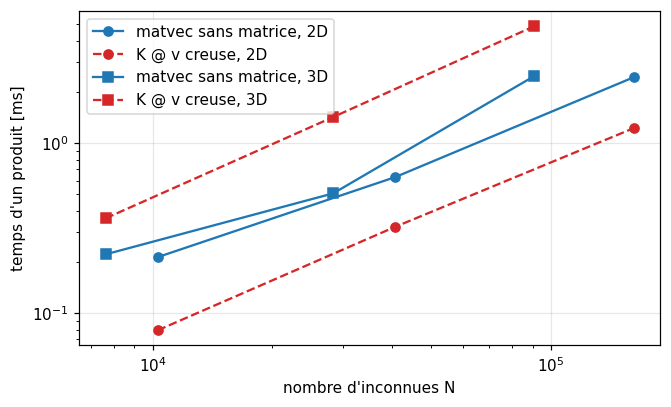

In [12]:
def chrono(fn, rep=5):
    fn()
    t0 = time.perf_counter()
    for _ in range(rep):
        fn()
    return (time.perf_counter() - t0) / rep

lignes = []
for shape in [(100, 50), (200, 100), (400, 200), (20, 10, 10), (40, 20, 10), (60, 30, 15)]:
    op, _ = cantilever(shape)
    w = torch.ones(op.grid.n_elems); v = torch.randn(op.n_dofs); vn = v.numpy()
    t0 = time.perf_counter(); K = op.assemble_csr(w); t_premier = time.perf_counter() - t0
    t_suivant = chrono(lambda: op.assemble_csr(w * 1.1), rep=2)
    lignes.append((shape, op.n_dofs, chrono(lambda: op.matvec(w, v)), chrono(lambda: K @ vn), t_premier, t_suivant))

print(f"{'maillage':>12} | {'N':>7} | {'matvec':>9} | {'K@v creuse':>10} | {'assemb. 1er':>11} | {'assemb. suiv.':>13}")
for shape, N, tm, tk, t1, t2 in lignes:
    print(f"{str(shape):>12} | {N:7d} | {tm * 1e3:7.2f} ms | {tk * 1e3:8.2f} ms | {t1:9.2f} s | {t2:11.3f} s")

fig, ax = plt.subplots(figsize=(6.2, 3.8))
for d, mk in ((2, "o"), (3, "s")):
    sel = [l for l in lignes if len(l[0]) == d]
    ax.loglog([l[1] for l in sel], [l[2] * 1e3 for l in sel], mk + "-", color="C0", label=f"matvec sans matrice, {d}D")
    ax.loglog([l[1] for l in sel], [l[3] * 1e3 for l in sel], mk + "--", color="C3", label=f"K @ v creuse, {d}D")
ax.set_xlabel("nombre d'inconnues N"); ax.set_ylabel("temps d'un produit [ms]"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Sur cette machine :

- le `matvec` sans matrice est du même ordre de grandeur que le produit creux, mais 2 à 3 fois plus **lent** en 2D (la matrice y a $\approx18$ coefficients par ligne : peu à lire) et 1,6 à 2,6 fois plus **rapide** en 3D (la matrice y a $\approx77$ coefficients par ligne, un volume de mémoire à lire bien supérieur à celui de `edof`) ;
- l'assemblage coûte beaucoup plus qu'un produit (il faut y trier les $N_e\,m^2$ contributions la première fois ; l'appel suivant est environ 10 fois plus rapide car le motif est mémorisé) ;
- les coûts croissent à peu près comme $N$ : un `matvec` est linéaire en $N$.

Ces temps dépendent de la machine et du nombre de fils de calcul de PyTorch ; il faut retenir les **ordres de grandeur et la tendance**, pas les valeurs absolues. Ce qui compte pour l'optimisation : le produit n'a besoin ni d'assemblage ni de gros tenseurs, et l'opérateur est directement différentiable en $w$ (voir la vérification du §4).

## 6. Le même code pour une inconnue par nœud

L'écoulement potentiel du projet (leçon 14) est le même problème avec **une** inconnue par nœud : la matrice élémentaire est celle de la diffusion, $\mathbf K_e^0=\int\nabla\mathbf N^\top\nabla\mathbf N\,dV$ ($4\times4$ en 2D), et `w` joue le rôle de la conductivité. `StructuredFEOperator` ne connaît ni l'élasticité ni SIMP, seulement `ncomp` : on peut donc le tester sur le problème de Poisson du notebook 5, $-\Delta T=2\pi^2\sin(\pi x)\sin(\pi z)$ sur le carré unité, $T=0$ au bord, dont la solution exacte est $\sin(\pi x)\sin(\pi z)$.

In [13]:
def poisson_op(n):
    h = 1.0 / n
    g = Grid((n, n), (h, h))
    xs = torch.arange(n + 1) * h
    X, Z = torch.meshgrid(xs, xs, indexing="ij")
    bord = torch.zeros(n + 1, n + 1, dtype=torch.bool)
    bord[0, :] = bord[-1, :] = bord[:, 0] = bord[:, -1] = True
    return StructuredFEOperator(g, Connectivity(g, 1), laplace_q1(2, g.h), 1, bord.reshape(-1)), X, Z, h

print(f"{'n':>4} | {'erreur max':>10} | ordre | itérations CG (f = sin sin) | itérations CG (f = 1)")
prec = None
for n in (8, 16, 32, 64, 128):
    op, X, Z, h = poisson_op(n)
    w = torch.ones(op.grid.n_elems)
    exact = (torch.sin(math.pi * X) * torch.sin(math.pi * Z)).reshape(-1)
    f = (h * h * 2 * math.pi**2 * torch.sin(math.pi * X) * torch.sin(math.pi * Z)).reshape(-1) * op.free_mask
    cg = TorchCG(tol=1e-12).prepare(op, w)
    u = cg.solve(f); it_sin = cg.last.iterations
    erreur = float((u - exact).abs().max())
    cg.solve(torch.full_like(f, h * h) * op.free_mask); it_cst = cg.last.iterations
    ordre = "" if prec is None else f"{math.log2(prec / erreur):.2f}"
    prec = erreur
    print(f"{n:4d} | {erreur:10.2e} | {ordre:>5} | {it_sin:27d} | {it_cst:d}")

   n | erreur max | ordre | itérations CG (f = sin sin) | itérations CG (f = 1)
   8 |   3.93e-02 |       |                           1 | 10
  16 |   9.69e-03 |  2.02 |                           1 | 24
  32 |   2.41e-03 |  2.01 |                           1 | 50
  64 |   6.03e-04 |  2.00 |                           1 | 101


 128 |   1.51e-04 |  2.00 |                           1 | 204


L'erreur de discrétisation décroît à l'**ordre 2** (le facteur 4 par doublement du maillage, soit un exposant de $2{,}00$), comme au notebook 5 : l'opérateur `ncomp=1` fait la même chose qu'une matrice de Poisson. Un détail instructif concerne les itérations : avec $f=\sin\sin$ le CG converge en **une itération**. Ce second membre est un vecteur propre de la matrice discrète, et le CG, qui construit la solution dans l'espace de Krylov engendré par $\mathbf f$ ($\mathbf f,\mathbf K\mathbf f,\mathbf K^2\mathbf f,\dots$), trouve la solution dès la première direction. Ce n'est pas représentatif : pour mesurer le comportement d'un solveur itératif, il faut un second membre **générique** (ici $f=1$, qui excite beaucoup de modes), et alors les itérations croissent avec $n$ comme au notebook 5.

## 7. Brancher l'opérateur dans les solveurs

Le notebook 5 avait laissé en suspens `ScipyDirect.prepare(op, w)` et `TorchCG.prepare(op, w)`. Ils sont maintenant branchés :

- `ScipyDirect.prepare` assemble `op.assemble_csr(w)` et en garde la factorisation ;
- `TorchCG.prepare` passe au CG la fonction $\mathbf v\mapsto$ `op.matvec(w, v)` et le préconditionneur de Jacobi construit avec `op.diag(w)`.

On les compare sur la poutre MBB (demi-poutre : appui à rouleau en bas à droite, symétrie à gauche, force en haut à gauche) en $60\times20$, avec une densité aléatoire $\rho$ et $w=\varepsilon_s+(1-\varepsilon_s)\rho^3$ (contraste $10^{3}$), puis sur une console 3D. D'abord la forme déformée (densité uniforme) et la convergence.

direct (LU creux)        :    7.1 ms, fill-in 4.1
CG sans matrice,  aucun :  100.2 ms,  1136 itérations, écart au direct 1.4e-12
CG sans matrice, Jacobi :   70.6 ms,   795 itérations, écart au direct 1.4e-12


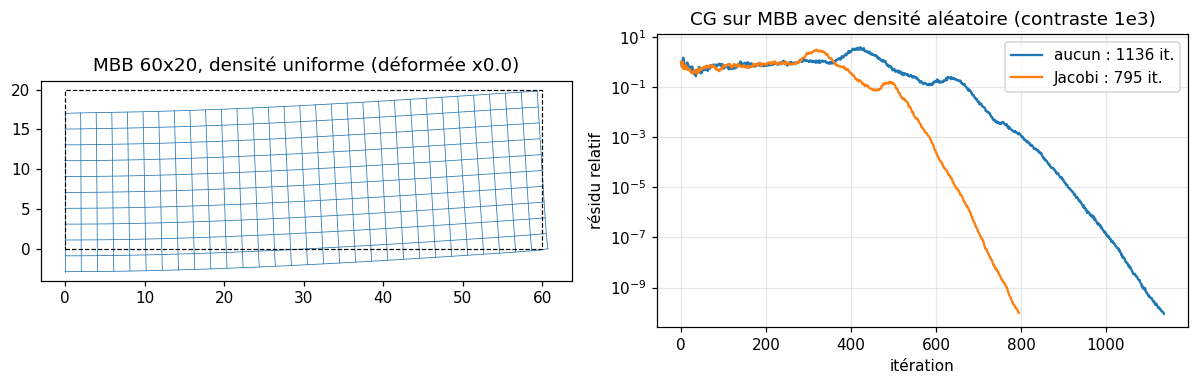

In [14]:
def mbb(nx, nz):
    g = Grid((nx, nz), (1.0, 1.0))
    Ke0 = el.elasticity_ke0(2, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(2, "stress"))
    nzn = nz + 1
    fixed = torch.zeros(g.n_dofs(2), dtype=torch.bool)
    fixed[0 : 2 * nzn : 2] = True                       # symétrie : u_x = 0 sur la face x = 0
    fixed[2 * (g.n_nodes - nzn) + 1] = True             # rouleau : u_z = 0 au coin bas droit
    f = torch.zeros(g.n_dofs(2)); f[2 * (nzn - 1) + 1] = -1.0   # force unitaire en haut à gauche
    return StructuredFEOperator(g, Connectivity(g, 2), Ke0, 2, fixed), f

op, f = mbb(60, 20)
rho = torch.rand(op.grid.n_elems, generator=torch.Generator().manual_seed(1))
w = 1e-3 + (1 - 1e-3) * rho**3

t0 = time.perf_counter(); direct = ScipyDirect().prepare(op, w); u_dir = direct.solve(f * op.free_mask); t_dir = time.perf_counter() - t0
res = {}
for nom, prec in (("none", "aucun"), ("jacobi", "Jacobi")):
    t0 = time.perf_counter()
    cg = TorchCG(tol=1e-10, preconditioner=nom).prepare(op, w)
    u_cg = cg.solve(f * op.free_mask)
    res[prec] = (cg.last, time.perf_counter() - t0, float(torch.linalg.norm(u_cg - u_dir) / torch.linalg.norm(u_dir)))
print(f"direct (LU creux)        : {t_dir * 1e3:6.1f} ms, fill-in {direct.fill_in:.1f}")
for prec, (r, t, ecart) in res.items():
    print(f"CG sans matrice, {prec:>6} : {t * 1e3:6.1f} ms, {r.iterations:5d} itérations, écart au direct {ecart:.1e}")

# forme déformée (densité uniforme)
w1 = torch.ones(op.grid.n_elems)
u1 = ScipyDirect().prepare(op, w1).solve(f * op.free_mask).reshape(-1, 2)
nx, nz = op.grid.shape
X, Z = np.meshgrid(np.arange(nx + 1), np.arange(nz + 1), indexing="ij")
amp = 3.0 / float(u1.abs().max())
Xd, Zd = X + amp * u1[:, 0].reshape(nx + 1, nz + 1).numpy(), Z + amp * u1[:, 1].reshape(nx + 1, nz + 1).numpy()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for i in range(0, nx + 1, 2): axs[0].plot(Xd[i], Zd[i], color="C0", lw=0.5)
for j in range(0, nz + 1, 2): axs[0].plot(Xd[:, j], Zd[:, j], color="C0", lw=0.5)
axs[0].plot([0, nx, nx, 0, 0], [0, 0, nz, nz, 0], "k--", lw=0.8)
axs[0].set_aspect("equal"); axs[0].set_title(f"MBB 60x20, densité uniforme (déformée x{amp:.1f})")
for prec, (r, t, ecart) in res.items():
    axs[1].semilogy(r.residuals, label=f"{prec} : {r.iterations} it.")
axs[1].set_xlabel("itération"); axs[1].set_ylabel("résidu relatif"); axs[1].legend(); axs[1].grid(alpha=0.3)
axs[1].set_title("CG sur MBB avec densité aléatoire (contraste 1e3)")
plt.tight_layout(); plt.show()

Les deux solveurs donnent la même solution (écart de l'ordre de $10^{-12}$, bien en deçà du seuil $10^{-6}$ du contrat C-SOLVE-07). Jacobi réduit ici les itérations de 1136 à 795 ; son effet croît avec le contraste (notebook 5). Sur ce petit cas 2D (2 600 inconnues), le solveur direct reste plus rapide : le sans-matrice ne devient intéressant que lorsque la mémoire et le remplissage comptent, c'est-à-dire en 3D.

Voici la console 3D, résolue par les deux voies depuis le **même opérateur**, avec une densité SIMP aléatoire ($p=3$, $\varepsilon_s=10^{-3}$). Le temps du solveur direct inclut l'assemblage creux ; celui du CG n'inclut rien d'autre que ses itérations.

In [15]:
print(f"{'maillage':>10} | {'N':>6} | {'direct (assemblage + LU + solve)':>32} | {'CG Jacobi sans matrice':>24} | écart")
for shape in [(20, 8, 8), (30, 10, 10), (40, 12, 12)]:
    op, f = cantilever(shape)
    rho = torch.rand(op.grid.n_elems, generator=torch.Generator().manual_seed(0))
    w = 1e-3 + (1 - 1e-3) * rho**3
    t0 = time.perf_counter(); h = ScipyDirect().prepare(op, w); u_d = h.solve(f); t_d = time.perf_counter() - t0
    t0 = time.perf_counter(); c = TorchCG(tol=1e-8).prepare(op, w); u_c = c.solve(f); t_c = time.perf_counter() - t0
    ecart = float(torch.linalg.norm(u_c - u_d) / torch.linalg.norm(u_d))
    print(f"{str(shape):>10} | {op.n_dofs:6d} | {t_d:30.2f} s | {t_c:14.2f} s, {c.last.iterations:4d} it. | {ecart:.0e}")

  maillage |      N | direct (assemblage + LU + solve) |   CG Jacobi sans matrice | écart


(20, 8, 8) |   5103 |                           0.13 s |           0.06 s,  417 it. | 2e-11


(30, 10, 10) |  11253 |                           0.54 s |           0.18 s,  584 it. | 1e-11


(40, 12, 12) |  20787 |                           1.92 s |           0.37 s,  744 it. | 8e-12


De cinq mille à vingt mille inconnues, le CG sans matrice est déjà 2 à 5 fois plus rapide que la voie directe, et l'écart croît avec la taille (le solveur direct subit le remplissage 3D du notebook 4). Cette comparaison reste celle d'un **cube simple** avec densité aléatoire ; avec une vraie topologie en cours d'optimisation (matière concentrée, grands vides), le nombre d'itérations peut être très supérieur (notebook 5 : près de $1{,}5\times10^4$ itérations pour le treillis 2D à $\varepsilon_s=10^{-9}$ sans préconditionneur) et le multigrille de la phase 6 deviendra nécessaire.

**Départ à chaud.** Au cours de l'optimisation, la densité change peu entre deux itérations ; partir de la solution précédente devrait faire gagner des itérations. On le mesure : on résout pour $w$, puis pour $w$ perturbé de $\pm\delta$ (aléatoirement, élément par élément), à froid ou à chaud.

In [16]:
op, f = cantilever((40, 10, 10))
gw = torch.Generator().manual_seed(0)
w0 = 1e-3 + (1 - 1e-3) * torch.rand(op.grid.n_elems, generator=gw) ** 3
c = TorchCG(tol=1e-8).prepare(op, w0); u0 = c.solve(f)
print(f"solution de départ : {c.last.iterations} itérations à froid")
print(f"{'perturbation':>13} | {'à froid':>8} | {'à chaud':>8} | gain")
for delta in (1e-5, 1e-4, 1e-3, 1e-2):
    w1 = w0 * (1 + delta * (2 * torch.rand(w0.shape, generator=gw) - 1))
    c = TorchCG(tol=1e-8).prepare(op, w1)
    c.solve(f); froid = c.last.iterations
    c.solve(f, x0=u0); chaud = c.last.iterations
    print(f"{delta:13.0e} | {froid:8d} | {chaud:8d} | {100 * (1 - chaud / froid):3.0f} %")

solution de départ : 736 itérations à froid
 perturbation |  à froid |  à chaud | gain


        1e-05 |      736 |      573 |  22 %


        1e-04 |      736 |      669 |   9 %


        1e-03 |      736 |      689 |   6 %


        1e-02 |      736 |      708 |   4 %


Le gain est **modeste** (quelques pour cent à une vingtaine de pour cent) : le départ à chaud réduit le résidu initial mais le CG est limité par le spectre de la matrice, pas par le point de départ. Il ne faut donc pas compter dessus pour diviser les itérations par dix. (Ici la perturbation est aléatoire donc rugueuse ; on n'a pas mesuré le cas d'une variation lisse.)

## 8. Limites et pièges

- **`index_add_` n'est pas déterministe sur GPU.** L'ordre d'addition des contributions n'est pas fixé, donc l'arrondi change d'une exécution à l'autre ; sur CPU en `float64` (référence du projet) il est déterministe. À garder en tête pour les tests sur GPU (C-CONV-09).
- **Le coût du `matvec` est $N_e\,m^2$ opérations.** En 3D ($m=24$) c'est 576 multiplications-additions par élément contre ~250 pour la matrice creuse : le sans-matrice fait plus de calcul mais bien moins d'accès mémoire, et c'est la mémoire qui limite ; l'avantage observé (×2 en 3D) ne vaut pas forcément sur une autre machine.
- **`assemble_csr` reste coûteux en mémoire** (tenseur $N_e\,m\,m$ et copies de tri : près de 1,5 Go au budget 3D). Elle sert aux solveurs directs et aux petits cas ; ne pas l'appeler à chaque itération d'optimisation en 3D.
- **Le résidu du solveur direct plafonne avec le conditionnement.** Pour la poutre élancée ($L/H=10$) à $160\times16$ puis $320\times32$, le résidu relatif de LU atteint $1{,}4\times10^{-10}$ puis $4\times10^{-10}$, au-dessus du seuil par défaut $10^{-10}$ du contrat C-SOLVE-02, car le résidu d'un solveur stable vaut environ $\varepsilon_{\text{mach}}\,\|\mathbf K\|\|\mathbf u\|/\|\mathbf f\|$, et ce rapport est de l'ordre du conditionnement. Un seuil relatif à $\|\mathbf f\|$ est donc irréaliste sur des poutres élancées ou à fort contraste. *Suite donnée (notebook 9) :* le contrat C-SOLVE-02 porte désormais, pour les solveurs directs, sur l'**erreur inverse normwise** $\|\mathbf K\mathbf u-\mathbf f\|/(\|\mathbf K\|_1\|\mathbf u\|+\|\mathbf f\|)$, qui reste de l'ordre de $\varepsilon_{\text{mach}}$ quel que soit le conditionnement. Dans ce notebook, exécuté avant ce changement, la tolérance du direct a été portée à $10^{-8}$ pour ces cas ; elle n'est plus nécessaire.
- **Ke0 unique = grille régulière.** Dès qu'on voudrait des éléments différents (maillage non uniforme, géométrie courbe), il faudrait une matrice par élément et le principe change (tenseur $N_e\times m\times m$ ou recalcul à la volée).

## Bilan

| Constat | Où c'est dans le code |
|---|---|
| $\mathbf K\mathbf v=\sum_e\mathbf A_e^\top w_e\mathbf K_e^0\mathbf A_e\mathbf v$ : rassembler, multiplier (un seul $\mathbf K_e^0$), ajouter | `StructuredFEOperator.matvec` |
| Le *scatter-add* se fait avec `index_add_`, pas `+=` sur un index avancé | `matvec`, `diag`, `assemble_csr` |
| Appuis : $\widetilde{\mathbf K}=\mathbf P\mathbf K\mathbf P+(\mathbf I-\mathbf P)$, SPD, même taille | `free_mask`, C-OP-01 et C-OP-06 |
| Validé contre un assemblage par boucles (2D, 3D), `gradcheck`, différences finies | `tests/unit/test_operator.py` (C-OP-01 à 07) |
| Diagonale exacte pour Jacobi ; contraction $\boldsymbol\lambda_e^\top\mathbf K_e^0\mathbf u_e$ pour l'adjoint | `diag`, `dK_contract` |
| Motif creux mémorisé, seules les valeurs recalculées | `assemble_csr` (C-OP-03) |
| Jamais de tenseur $N_e\times m\times m$ dans `matvec` ; mémoire ≈ quelques dizaines de Mo au budget 3D | C-OP-07, C-PERF-02 |
| Même opérateur pour `ncomp=1` (Poisson, ordre 2) | `ncomp` |
| `prepare(op, w)` branché pour le direct et pour le CG Jacobi | `ScipyDirect.prepare`, `TorchCG.prepare` (C-SOLVE-07) |

**Pour expérimenter.** (i) Au §2, remplacez `index_add_` par `y[edof] += fe` dans `StructuredFEOperator.matvec` (en copie du fichier) et relancez `pytest tests/unit/test_operator.py` : quels contrats échouent ? (ii) Au §6, remplacez le second membre par une fonction de $x$ seul, $q=\sin(\pi x)$ : le CG converge-t-il encore en une itération (à $n=32$ il en faut 16) ? Pourquoi ? (iii) Au §5, mesurez le `matvec` avec `torch.set_num_threads(1)` : l'avantage 3D face à la matrice creuse subsiste-t-il ? (iv) Au §7, mettez un $w$ à $\varepsilon_s=10^{-9}$ dans la console 3D : combien d'itérations faut-il à Jacobi ?

*Suite : leçon 7 (l'état adjoint, qui utilise `dK_contract` et la factorisation réutilisable). Voir le [plan des leçons](README.md).*